# 14 · 个性化：在游戏里悄悄适应每个玩家

**问题。**notebook 10 发现错误高度集中在少数人身上（手指测试集 177 人里 102 人一个错都没有，最差的 5% 的人贡献了三分之一的错误），触控笔上一位书写者的固定写法（`pd-b13` 的 4）任何通用模型都认不对。这正是个性化该解决的：**见过这个人写几次，就认得他的写法**。

notebook 04 在合成书写者上试过：冻结卷积层、只微调最后两层（4,810 个参数），每个数字 5 个样本就能把错误减少约 70%。但那是合成数据，而且假设了"每个数字都有干净的标签"。这一本在**真实书写者**上重做，并且模拟**游戏里真实能拿到的标签**。

**两种标签来源：**

1. **校准**（上界）：让玩家每个数字写 $k$ 遍，标签完全正确。准确但打扰玩家。
2. **无感（游戏中）**：玩家正常玩，游戏只把**被判定为打中**的书写加入个性化数据，标签是游戏判定的那个数字（屏幕上 3 个答案，用现在的 `decide()`）。玩家不需要做任何事，但：只有模型本来就能（大致）认出的样本才会被加入，而且偶尔标签是错的（打错了妖怪）。

**两种适应方法**（来自 notebook 04）：

- **头部微调**：冻结卷积部分，用 Adam 在这个人的样本上微调最后两层全连接，加 L2 约束不要离原模型太远。浏览器里实测过（04 的 `export/bench.html`）。
- **原型**：不训练，把这个人每个数字的样本特征平均成"原型"，和模型原本的概率合并。

**基础模型：**09 的图像模型 C（上线配方）和 12 的 resnet（目前最好的图像模型），都用种子 42。个性化只改图像模型；如果上线的是"图像 + 轨迹"融合，适应后的图像概率再和轨迹模型融合（第 6 节）。

**协议。**每个测试书写者单独做：随机打乱他的样本，前一部分作为适应数据，**其余的**作为测试，绝不重叠。超参数在验证书写者（Pendigits val 6 人 + Corr dev 76 人）上选。

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

sys.path.insert(0, '.')
import evaluate, recipe

REAL = Path('cache/real'); RESULTS = Path('results'); MODEL_DIR = Path('cache/models')
plt.rcParams['figure.dpi'] = 110

meta, x_real = recipe.real_meta()
y = meta.label.to_numpy()
SPLITS = recipe.eval_splits(meta)
writers_of = lambda idx: meta.writer.to_numpy()[idx]
P12b = dict(np.load(REAL / 'probs12b.npz'))
r12 = json.loads((RESULTS / '12_image_architectures.json').read_text(encoding='utf-8'))
PT = P12b['trajectory (11)|42']                                 # notebook 11's trajectory model, seed 42

## 1. 拆开模型：冻结的特征 + 可调的头

全局平均池化之前的部分冻结，输出每个样本的特征向量；后面的 `embedding`（64）和 `classifier`（10）两层是"头"。特征对所有真实样本只算一次。

In [2]:
def split_model(m):
    gap = next(l for l in m.layers if isinstance(l, keras.layers.GlobalAveragePooling2D))
    feat = keras.Model(m.inputs, gap.output)
    W0 = [w.numpy() for w in m.get_layer('embedding').weights + m.get_layer('classifier').weights]
    return feat.predict(x_real[..., None], batch_size=2048, verbose=0), W0

def head_forward(f, W, emb_only=False):
    e = tf.nn.relu(f @ W[0] + W[1])
    return e if emb_only else tf.nn.softmax(e @ W[2] + W[3])

@tf.function(reduce_retracing=True)
def _adam(f, yy, W0, steps, lr, l2):
    """Plain Adam on the head (the same loop as export/bench.html runs in the browser)."""
    W, m, v = list(W0), [tf.zeros_like(w) for w in W0], [tf.zeros_like(w) for w in W0]
    for t in tf.range(1, steps + 1):
        with tf.GradientTape() as tape:
            tape.watch(W)
            p = head_forward(f, W)
            loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(yy, p))
            loss += l2 * tf.add_n([tf.reduce_sum((w - w0) ** 2) for w, w0 in zip(W, W0)])
        g = tape.gradient(loss, W)
        tt = tf.cast(t, tf.float32)
        m = [0.9 * a + 0.1 * b for a, b in zip(m, g)]
        v = [0.999 * a + 0.001 * b * b for a, b in zip(v, g)]
        W = [w - lr * (a / (1 - 0.9 ** tt)) / (tf.sqrt(b / (1 - 0.999 ** tt)) + 1e-7) for w, a, b in zip(W, m, v)]
    return W

def finetune(f_s, y_s, W0, steps, lr, l2):
    W = _adam(tf.constant(f_s), tf.constant(y_s.astype(np.int32)), [tf.constant(w) for w in W0],
              tf.constant(steps), tf.constant(lr), tf.constant(l2))
    return [w.numpy() for w in W]

def proto_probs(f_s, y_s, f_q, W0, tau):
    """Base log-probabilities + tau x cosine similarity to this writer's digit prototypes (digits seen so far)."""
    norm = lambda e: e / (np.linalg.norm(e, axis=1, keepdims=True) + 1e-8)
    e_s, e_q = head_forward(f_s, W0, True).numpy(), head_forward(f_q, W0, True).numpy()
    z = np.log(head_forward(f_q, W0).numpy() + 1e-9)
    for d in np.unique(y_s):
        z[:, d] += tau * (norm(e_q) @ norm(e_s[y_s == d].mean(0, keepdims=True)).T)[:, 0]
    z -= z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

BASES = {}
for name, path in [('image C (09)', 'real09_C_s42.keras'), ('resnet (12)', 'arch12_resnet_s42.keras')]:
    t0 = time.time()
    BASES[name] = split_model(keras.models.load_model(MODEL_DIR / path))
    print(name, 'features', BASES[name][0].shape, f'{time.time() - t0:.0f} s')

image C (09) features (31066, 64) 15 s


resnet (12) features (31066, 64) 31 s


## 2. 适应数据从哪来

`support(...)` 为一个书写者挑出适应用的样本和标签，其余样本是他的测试数据：

- `calib`：每个数字取 $k$ 个，标签正确；
- `game`：按随机顺序"玩" $n$ 次，每次屏幕上 3 个答案（含正确答案），基础模型 + 现在的 `decide()` 判定为打中的样本加入适应数据，**标签是被打中的数字**（可能是错的）；
- `game + noise`：同上，再把 10% 的标签故意随机换掉，测试对错误标签有多敏感。

In [3]:
def support(idx, mode, k_or_n, base_p, rng):
    idx = rng.permutation(idx)
    if mode == 'calib':
        s = np.concatenate([idx[y[idx] == d][:k_or_n] for d in range(10)])
        return s, y[s], np.setdiff1d(idx, s)
    played, rest = idx[:k_or_n], idx[k_or_n:]
    keep, lab = [], []
    for i in played:
        others = rng.choice([d for d in range(10) if d != y[i]], 2, replace=False)
        kind, d = evaluate.decide(base_p[i], set(others) | {y[i]})
        if kind == 'hit':
            keep.append(i); lab.append(d)
    lab = np.array(lab, int)
    if mode == 'game + noise' and len(lab):
        flip = rng.random(len(lab)) < 0.10
        lab[flip] = (lab[flip] + rng.integers(1, 10, flip.sum())) % 10
    return np.array(keep, int), lab, rest

def evaluate_writer(base, idx, mode, k_or_n, method, hp, rng, fuse_w=None):
    f, W0 = BASES[base]
    s, ys, q = support(idx, mode, k_or_n, _full_base(base, fuse_w), rng)   # in-game labels come from what the game reads
    if len(q) == 0:                                    # a writer with too few samples to test on (a few Corr writers)
        return np.nan, np.nan, len(s), np.nan
    p0 = head_forward(f[q], W0).numpy()
    if len(s) == 0 or method == 'none':
        p1 = p0
    elif method == 'head':
        p1 = head_forward(f[q], finetune(f[s], ys, W0, **hp)).numpy()
    else:
        p1 = proto_probs(f[s], ys, f[q], W0, **hp)
    if fuse_w is not None:
        fz = lambda p: _fuse(p, PT[q], fuse_w)
        p0, p1 = fz(p0), fz(p1)
    return (p0.argmax(1) == y[q]).mean(), (p1.argmax(1) == y[q]).mean(), len(s), (ys != y[s]).mean() if len(s) else 0.0

_FULL = {}
def _full_base(base, fuse_w=None):
    """The game's reading of every sample before any adaptation: the image model, or its fusion with the trajectory model."""
    if (base, fuse_w) not in _FULL:
        f, W0 = BASES[base]
        p = head_forward(f, W0).numpy()
        _FULL[(base, fuse_w)] = p if fuse_w is None else _fuse(p, PT, fuse_w)
    return _FULL[(base, fuse_w)]

def _fuse(p_img, p_traj, w):
    z = w * np.log(p_img + 1e-7) + (1 - w) * np.log(p_traj + 1e-7)
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def writers(split):
    idx = SPLITS[split]; w = writers_of(idx)
    return {k: idx[w == k] for k in np.unique(w)}

## 3. 超参数（验证书写者，图像模型 C，`calib`，每个数字 2 个）

In [4]:
VAL_W = {**writers('val: pen'), **writers('val: finger')}
GRID = {'head': [dict(steps=s, lr=3e-3, l2=l) for s in (50, 100) for l in (1e-3, 1e-2, 1e-1)],
        'proto': [dict(tau=t) for t in (1.0, 3.0, 10.0)]}
HP = {}
for method, options in GRID.items():
    scores = []
    for hp in options:
        rng = np.random.default_rng(0)
        scores.append(np.mean([evaluate_writer('image C (09)', idx, 'calib', 2, method, hp, rng)[1] for idx in VAL_W.values()]))
    HP[method] = options[int(np.argmax(scores))]
    print(method, [f'{100 * s:.2f}' for s in scores], '-> chosen', HP[method])

head ['99.28', '99.25', '99.19', '99.30', '99.25', '99.19'] -> chosen {'steps': 100, 'lr': 0.003, 'l2': 0.001}


proto ['98.94', '99.02', '99.18'] -> chosen {'tau': 10.0}


## 4. 校准式个性化：每个数字写 $k$ 遍

手指书写者每个数字只有 8 个样本，所以 $k \le 4$（剩下的做测试）；触控笔书写者约 25 个，$k$ 可以到 10。下表是**所有测试书写者的平均准确率**（每个书写者权重相同）。

In [5]:
TEST_W = {'pen': writers('test: pen'), 'finger': writers('test: finger')}
KS = {'pen': [0, 1, 2, 5, 10], 'finger': [0, 1, 2, 4]}
rows = []
t0 = time.time()
for base in BASES:
    for dev, ws in TEST_W.items():
        for k in KS[dev]:
            for method in (['none'] if k == 0 else ['head', 'proto']):
                rng = np.random.default_rng(1)
                for wname, idx in ws.items():
                    a0, a1, n, _ = evaluate_writer(base, idx, 'calib', max(k, 0), method, HP.get(method, {}), rng)
                    rows.append({'base': base, 'device': dev, 'k': k, 'method': method, 'writer': wname, 'before': a0, 'after': a1, 'support': n})
calib = pd.DataFrame(rows)
print(f'{(time.time() - t0) / 60:.1f} min')
tab = calib.groupby(['base', 'device', 'method', 'k']).after.mean().unstack('k') * 100
tab.round(2)

1.4 min


k                              0      1      2      4      5      10
base         device method                                          
image C (09) finger head      NaN  99.10  99.24  99.45    NaN    NaN
                    none    98.84    NaN    NaN    NaN    NaN    NaN
                    proto     NaN  99.02  99.07  99.15    NaN    NaN
             pen    head      NaN  98.87  99.10    NaN  99.57  99.76
                    none    98.40    NaN    NaN    NaN    NaN    NaN
                    proto     NaN  98.78  98.91    NaN  99.11  99.14
resnet (12)  finger head      NaN  99.39  99.46  99.60    NaN    NaN
                    none    99.26    NaN    NaN    NaN    NaN    NaN
                    proto     NaN  99.38  99.40  99.57    NaN    NaN
             pen    head      NaN  98.78  98.88    NaN  99.32  99.57
                    none    98.23    NaN    NaN    NaN    NaN    NaN
                    proto     NaN  98.30  98.29    NaN  98.36  98.33

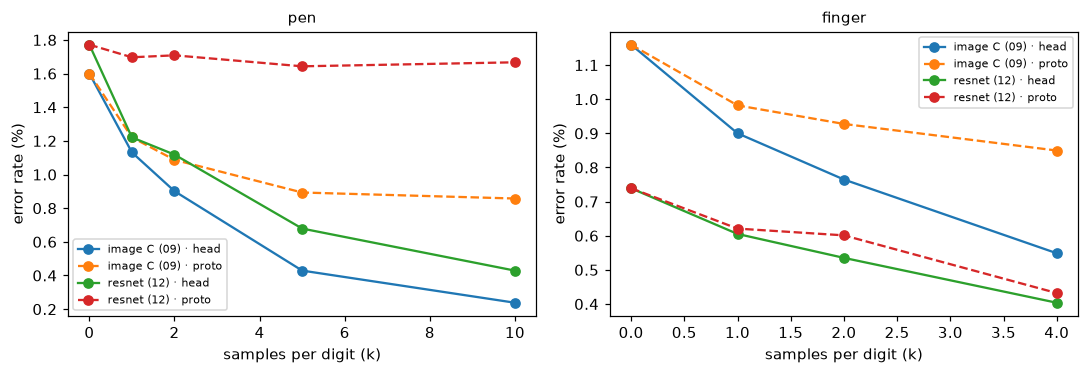

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, dev in zip(axes, ['pen', 'finger']):
    for base in BASES:
        for method, st in [('head', '-'), ('proto', '--')]:
            d = calib[(calib.base == base) & (calib.device == dev) & ((calib.method == method) | (calib.k == 0))]
            m = d.groupby('k').after.mean()
            ax.plot(m.index, 100 * (1 - m.values), st, marker='o', label=f'{base} · {method}')
    ax.set_xlabel('samples per digit (k)'); ax.set_ylabel('error rate (%)'); ax.set_title(dev, fontsize=10); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 4.1 谁受益：最难的书写者

平均数会掩盖个性化最重要的作用。下面是基础模型下最差的几位书写者，在头部微调后的变化；以及有没有人**变差**。

In [7]:
def who(base, dev, k):
    d = calib[(calib.base == base) & (calib.device == dev) & (calib.method == 'head') & (calib.k == k)].copy()
    d['gain'] = d.after - d.before
    worst = d.sort_values('before').head(6)[['writer', 'before', 'after']]
    return worst, (d.gain < -0.02).mean(), d.before.min(), d.after.min()

for dev, k in [('pen', 5), ('finger', 4)]:
    for base in BASES:
        worst, harmed, b_min, a_min = who(base, dev, k)
        print(f'{base} · {dev} · k={k}: worst writer {100 * b_min:.1f}% -> {100 * a_min:.1f}%; '
              f'writers more than 2 points worse after adapting: {100 * harmed:.1f}%')
        print((worst.set_index('writer') * 100).round(1).T.to_string()); print()

image C (09) · pen · k=5: worst writer 88.0% -> 98.5%; writers more than 2 points worse after adapting: 0.0%
writer  pd-b13  pd-b05  pd-b02  pd-b07  pd-b10  pd-b04
before    88.0    96.0    98.5    99.0    99.0    99.5
after     98.5    99.0    98.5    99.0    99.5   100.0

resnet (12) · pen · k=5: worst writer 86.0% -> 97.0%; writers more than 2 points worse after adapting: 0.0%
writer  pd-b13  pd-b05  pd-b11  pd-b04  pd-b07  pd-b08
before    86.0    97.0    97.0    99.0    99.0    99.0
after     97.0    97.5   100.0   100.0    99.0    99.0

image C (09) · finger · k=4: worst writer 89.5% -> 92.3%; writers more than 2 points worse after adapting: 1.7%
writer  co235  co285  co224  co253  co162  co136
before   89.5   89.7   90.0   92.1   92.5   92.5
after    97.4  100.0  100.0   97.4   95.0   95.0

resnet (12) · finger · k=4: worst writer 92.3% -> 94.7%; writers more than 2 points worse after adapting: 2.3%
writer  co285  co048  co162  co253  co037  co283
before   92.3   92.5   92.5   9

## 5. 无感个性化：只用游戏里打中的书写

玩 $n$ 次（$n$ = 10、20、40；手指书写者一般有 80 个样本，所以最多 40 次，剩下的做测试；少数样本不够的书写者在这一节不计），只有被判定为打中的才会加入。`label errors %` 是加入的样本里标签错误的比例。

In [8]:
NS = [10, 20, 40]
rows = []
for base in BASES:
    for dev, ws in TEST_W.items():
        for mode in ['game', 'game + noise']:
            for n in NS:
                for method in ['head', 'proto']:
                    rng = np.random.default_rng(2)
                    for wname, idx in ws.items():
                        a0, a1, ns, le = evaluate_writer(base, idx, mode, n, method, HP[method], rng)
                        rows.append({'base': base, 'device': dev, 'mode': mode, 'played': n, 'method': method, 'writer': wname,
                                     'before': a0, 'after': a1, 'kept': ns, 'label errors': le})
game = pd.DataFrame(rows)
g = game.groupby(['base', 'device', 'mode', 'method', 'played']).agg(before=('before', 'mean'), after=('after', 'mean'),
                                                                      kept=('kept', 'mean'), label_errors=('label errors', 'mean'))
g[['before', 'after', 'label_errors']] *= 100
g.round(2)

before  after   kept  \
base         device mode         method played                         
image C (09) finger game         head   10       98.80  98.22   9.92   
                                        20       98.80  98.73  19.80   
                                        40       98.56  99.03  39.59   
                                 proto  10       98.80  75.15   9.92   
                                        20       98.80  91.07  19.80   
                                        40       98.56  98.73  39.59   
                    game + noise head   10       98.83  91.47   9.90   
                                        20       98.80  90.14  19.80   
                                        40       98.75  92.89  39.59   
                                 proto  10       98.83  73.89   9.90   
                                        20       98.80  89.06  19.80   
                                        40       98.75  98.01  39.59   
             pen    game         head   10       98.45  98.24   9.86   
                                        20       98.45  98.20  19.79   
                                        40       98.43  98.43  39.50   
                                 proto  10       98.45  80.67   9.86   
                                        20       98.45  88.41  19.79   
                                        40       98.43  97.38  39.50   
                    game + noise head   10       98.39  91.04   9.93   
                                        20       98.48  93.72  19.64   
                                        40       98.26  90.67  39.71   
                                 proto  10       98.39  75.88   9.93   
                                        20       98.48  87.63  19.64   
                                        40       98.26  96.02  39.71   
resnet (12)  finger game         head   10       99.26  98.97   9.92   
                                        20       99.28  99.31  19.82   
                                        40       99.09  99.35  39.69   
                                 proto  10       99.26  90.83   9.92   
                                        20       99.28  95.90  19.82   
                                        40       99.09  99.23  39.69   
                    game + noise head   10       99.23  91.71   9.93   
                                        20       99.29  91.07  19.85   
                                        40       99.19  93.09  39.67   
                                 proto  10       99.23  87.47   9.93   
                                        20       99.29  93.58  19.85   
                                        40       99.19  98.65  39.67   
             pen    game         head   10       98.33  97.98   9.64   
                                        20       98.29  98.29  19.64   
                                        40       98.20  98.16  39.64   
                                 proto  10       98.33  91.13   9.64   
                                        20       98.29  92.39  19.64   
                                        40       98.20  97.96  39.64   
                    game + noise head   10       98.24  91.63   9.86   
                                        20       98.38  92.57  19.57   
                                        40       98.13  90.81  39.71   
                                 proto  10       98.24  89.10   9.86   
                                        20       98.38  90.27  19.57   
                                        40       98.13  96.63  39.71   

                                                label_errors  
base         device mode         method played                
image C (09) finger game         head   10              0.34  
                                        20              0.23  
                                        40              0.16  
                                 proto  10              0.34  
                                        20              0.23  
      

### 5.1 换成保守的设置

第 3 节的超参数是在**干净、均衡**的校准数据上选的（L2 = 0.001，几乎不约束）。游戏中的数据不均衡，还可能有错标签。下面用更强的 L2 约束（0.1 和 1.0）重跑游戏中 $n = 40$ 的情况，看能不能避免变差。

In [9]:
SAFE = [dict(steps=100, lr=3e-3, l2=1e-3), dict(steps=50, lr=3e-3, l2=1e-1), dict(steps=50, lr=1e-3, l2=1.0)]
rows = []
for base in BASES:
    for dev, ws in TEST_W.items():
        for mode in ['game', 'game + noise']:
            for hp in SAFE:
                rng = np.random.default_rng(2)
                r = [evaluate_writer(base, idx, mode, 40, 'head', hp, rng) for idx in ws.values()]
                rows.append({'base': base, 'device': dev, 'mode': mode, 'L2': hp['l2'],
                             'before': 100 * np.nanmean([a for a, *_ in r]), 'after': 100 * np.nanmean([b for _, b, *_ in r]),
                             'writers worse by > 2 points %': 100 * np.nanmean([b - a < -0.02 if a == a else np.nan for a, b, *_ in r])})
safe = pd.DataFrame(rows)
safe.round(2)

,base,device,mode,L2,before,after,writers worse by > 2 points %
0,image C (09),pen,game,0.0,98.43,98.43,0.00
1,image C (09),pen,game,0.1,98.43,98.40,0.00
2,image C (09),pen,game,1.0,98.43,98.43,0.00
3,image C (09),pen,game + noise,0.0,98.26,90.67,78.57
4,image C (09),pen,game + noise,0.1,98.26,95.98,28.57
5,image C (09),pen,game + noise,1.0,98.26,98.40,0.00
6,image C (09),finger,game,0.0,98.56,99.03,3.41
7,image C (09),finger,game,0.1,98.56,98.95,0.57
8,image C (09),finger,game,1.0,98.56,98.64,1.14
9,image C (09),finger,game + noise,0.0,98.75,92.89,71.02


### 5.2 触控笔那位固定写法的书写者

In [10]:
b13 = game[(game.writer == 'pd-b13') & (game.method == 'head') & (game['mode'] == 'game')][['base', 'played', 'before', 'after', 'kept']]
b13c = calib[(calib.writer == 'pd-b13') & (calib.method.isin(['head', 'none']))][['base', 'k', 'before', 'after']]
print('in-game (head):'); print((b13.set_index(['base', 'played']) * [100, 100, 1]).round(1).to_string()); print()
print('calibration (head):'); print((b13c.set_index(['base', 'k']) * 100).round(1).to_string())

in-game (head):
                     before  after  kept
base         played                     
image C (09) 10        87.9   86.2     8
             20        87.8   86.1    18
             40        86.2   85.7    38
resnet (12)  10        86.2   84.2     8
             20        86.5   86.5    18
             40        84.8   83.3    39

calibration (head):
                 before  after
base         k                
image C (09) 0     87.6   87.6
             1     87.5   94.6
             2     87.4   95.2
             5     88.0   98.5
             10    88.0   98.7
resnet (12)  0     86.0   86.0
             1     85.8   95.4
             2     85.7   95.7
             5     86.0   97.0
             10    86.0   98.0


## 6. 个性化 + 轨迹融合

上线的如果是"图像 + 轨迹"融合，个性化只调图像模型，然后照常和轨迹模型融合（权重用 notebook 12 为 resnet 选的 $w$）。以 resnet 为例，校准 $k = 2$ 和游戏中 $n = 40$。

In [11]:
W_RES = r12['fusion_with_trajectory']['resnet']['w']
rows = []
for dev, ws in TEST_W.items():
    for mode, kn in [('calib', 2), ('game', 40)]:
        rng = np.random.default_rng(3)
        for wname, idx in ws.items():
            a0, a1, _, _ = evaluate_writer('resnet (12)', idx, mode, kn, 'head', HP['head'], rng, fuse_w=W_RES)
            rows.append({'device': dev, 'mode': f'{mode} {kn}', 'writer': wname, 'fusion before': a0, 'fusion after': a1})
fz = pd.DataFrame(rows)
(fz.groupby(['device', 'mode'])[['fusion before', 'fusion after']].mean() * 100).round(2)

fusion before  fusion after
device mode                                
finger calib 2          99.52         99.61
       game 40          99.63         99.67
pen    calib 2          98.60         99.22
       game 40          98.57         99.05

## 7. 保存

In [12]:
out = {'hyperparameters': HP,
       'calibration': calib.groupby(['base', 'device', 'method', 'k'])[['before', 'after']].mean().reset_index().to_dict(orient='records'),
       'in_game': g.reset_index().to_dict(orient='records'),
       'in_game_l2': safe.round(3).to_dict(orient='records'),
       'fusion': fz.groupby(['device', 'mode'])[['fusion before', 'fusion after']].mean().reset_index().to_dict(orient='records')}
(RESULTS / '14_personalisation.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved results/14_personalisation.json')

saved results/14_personalisation.json


## 8. 结论

**1. 校准式个性化（让玩家每个数字写几遍）效果很好，而且安全。**（测试书写者的平均准确率；头部微调）

| 基础模型 | 设备 | 不适应 | 每个数字 1 个 | 2 个 | 4–5 个 | 10 个 |
|---|---|---|---|---|---|---|
| 图像 C | 手指 | 98.84% | 99.10% | 99.24% | **99.45%**（k=4） | — |
| 图像 C | 触控笔 | 98.40% | 98.87% | 99.10% | 99.57%（k=5） | **99.76%** |
| resnet | 手指 | 99.26% | 99.39% | 99.46% | **99.60%**（k=4） | — |
| resnet | 触控笔 | 98.23% | 98.78% | 98.88% | 99.32%（k=5） | 99.57% |

- 手指上，每个数字写 4 遍就把错误减少约一半（图像 C：1.16% → 0.55%）。触控笔上，每个数字 10 遍把错误减少 85%。
- **受益最大的正是最差的人**：那位固定写法的触控笔书写者（`pd-b13`）从 88% 提到 98.5%（k=5），他的 4 终于能认对了；手指上最差的几个人从 90% 左右提到 95–100%。
- 校准式适应后，手指书写者里只有约 2% 的人变差超过 2 个百分点，触控笔没有人变差。
- 头部微调明显好于原型法；原型法在 resnet + 触控笔上几乎无效。
- 和"图像 + 轨迹"融合叠加：resnet + 轨迹的融合，加上每个数字 2 个样本的校准，手指 99.52% → 99.61%，触控笔 98.60% → 99.22%。

**2. 无感个性化（只用游戏里打中的书写）几乎没有收益，而且对错标签很脆弱。**
- **收益小的原因**：游戏只会把"已经认对"的书写加进来，模型本来就会的东西再学一遍没用；真正需要学的样本（比如 `pd-b13` 的 4）恰恰因为认错了而进不来。图像 C 在手指上玩 40 次后从 98.56% 到 99.03%（+0.5 个百分点），触控笔上没有变化；玩 10 次反而下降（样本少、不均衡，过拟合）。`pd-b13` 玩 40 次后反而略降（图像 C：86.2% → 85.7%）。
- **一个例外**：如果游戏里跑的是"图像 + 轨迹"融合，融合能认出更多难样本，所以加进来的样本更有用：触控笔玩 40 次后 98.57% → 99.05%。
- **错标签的危害很大**：故意把 10% 的标签弄错后，用默认设置（L2 = 0.001）微调，平均准确率跌到 91–93%，约 70% 的人明显变差。原型法在样本少时也会崩（只给见过的数字加分，数字不全时会把其他数字挤掉）。
- **强约束能防止变差，但也消除了收益**：L2 = 1.0 时，10% 错标签下也基本不变差（变差超过 2 个百分点的人约 1%），但正常情况下也几乎没有提升。真实游戏里的错标签率估计只有 0.2–0.7%（表里 `label_errors`，即打错妖怪的比例），比 10% 低得多，所以中等约束（L2 = 0.1）是合理的折中。

**3. 给游戏的建议。**
- **主要做法：可选的"认识你的笔迹"小环节**，让玩家每个数字写 2–4 遍（20–40 笔，不到一分钟），标签由游戏给出所以完全正确。同样的微调循环 notebook 04 已经在浏览器里跑通并计时（`export/bench.html`）。按"玩家 + 输入工具"分别存（同一个人用手指和鼠标写的字不一样，这是 07 的决定），存在 localStorage，模型本身不变。
- **游戏中的数据只作补充**，而且只在用了融合模型时才有意义；必须用强约束（L2 ≥ 0.1），并且某个数字的样本少于 2 个时不调这个数字。
- **一个更有价值但还没实现的信号**：玩家重写后被认对的那一笔，说明前一笔被认错了。前一笔正是"需要学"的样本，标签就是后一笔的结果。这需要在游戏里记录"重写"事件，留作以后。

**局限。**没有鼠标数据，所以"按工具分别适应"的效果没法直接验证；Corr 的手指书写者每个数字只有 8 个样本，校准最多只能用到 $k = 4$。